In [1]:
import torch
import matplotlib.pyplot as plt
import numpy as np

In [2]:
class bsplines:

    def __init__(self, n_basis, degree):

        self.degree = degree
        self.n_basis = n_basis
        self.n_knots = n_basis + degree + 1

        # Uniform clamped bsplines
        self.knot_vector_init = torch.linspace(0, 1, self.n_knots - 2 * degree)
        self.nel = (self.knot_vector_init.shape[0]-1)**2
        self.knot_vector = torch.cat((
                torch.full((degree,),self. knot_vector_init[0]),
                self.knot_vector_init,
                torch.full((degree,), self.knot_vector_init[-1])
            ))
        

        # Same knot vector in every direction
        self.knot_x = self.knot_vector.clone()
        self.knot_y = self.knot_vector.clone()

        
        
        

        # 2D trained coefficients. -1 indicates that the parameter is not trained
        self.coeffs_trained = -torch.ones(n_basis, n_basis)
        self.coeffs_trained[0, :] = 0      # Top row
        self.coeffs_trained[-1, :] = 0     # Bottom row
        self.coeffs_trained[:, 0] = 0      # Left column
        self.coeffs_trained[:, -1] = 0     # Right column

        ##############Changes#####################
        # Trainable coefficients
        self.coeffs_trainable = torch.zeros(n_basis, n_basis, requires_grad=True)
        # self.coeffs_trainable = torch.rand(n_basis, n_basis, requires_grad=True)
        ##############Changes#####################


        # Define the connectivity of each element, i.e which bsplines have support in a specific element
        self.connectivity = []
        for i in range(self.n_basis - 3):
            for j in range(self.n_basis - 3):
                row = [i, i + self.degree, j, j + self.degree]
                self.connectivity.append(row)

        # Define the coordinates in each element x1, x2, y1, y2
        el_coordinates = []
        for i in range(self.knot_vector_init.shape[0]-1):
            for j in range(self.knot_vector_init.shape[0]-1):
                row = torch.tensor([self.knot_vector_init[i], self.knot_vector_init[i+1], self.knot_vector_init[j], self.knot_vector_init[j+1]])
                el_coordinates.append(row)
        self.el_coordinates = torch.stack(el_coordinates, dim=0)

        # Define the uniform random points in each element
        num_points=18
        self.X = torch.zeros(self.nel,num_points,2)
        for i in range(self.el_coordinates.shape[0]):

            i_range = (self.el_coordinates[i,0], self.el_coordinates[i,1])
            j_range = (self.el_coordinates[i,2], self.el_coordinates[i,3])

            i_vals = i_range[0] + (i_range[1] - i_range[0]) * torch.rand((num_points, 1))
            j_vals = j_range[0] + (j_range[1] - j_range[0]) * torch.rand((num_points, 1))
            self.X[i] = torch.cat([i_vals, j_vals], dim=1)

        # Define the points of the specific element
        
        

        ########### Changes###############
        # self.coeffs_trainable = torch.rand(4, 4, requires_grad=True)

        # # create the trainable matrix for each element
        # self.trainable_indices = []
        # for i in range(self.nel):        
        #     i_range = self.connectivity[i][0:2]
        #     j_range = self.connectivity[i][2:4]
        #     row=[]
        #     # To do: Here find the min and max for i, j. Based on this you can create the coeff.trainable matrix.
        #     for i in range(i_range[0], i_range[1]+1):
        #         for j in range(j_range[0], j_range[1]+1):

                    
        #             if self.coeffs_trained[i,j]==-1:

        #                 row.append([i,j])
        #                 self.coeffs_trained[i,j]=0

        #     if row:
        #         self.trainable_indices.append(row)


        # def matrix_from_shifted_indices(indices):
        #     # Get minimum and maximum indices
        #     min_i = min(i for i, _ in indices)
        #     max_i = max(i for i, _ in indices)
        #     min_j = min(j for _, j in indices)
        #     max_j = max(j for _, j in indices)

        #     # Compute shape of output matrix
        #     rows = max_i - min_i + 1
        #     cols = max_j - min_j + 1

        #     # # Initialize zero matrix
        #     # matrix = torch.zeros((rows, cols), dtype=torch.int)

        #     # # Place 1s at adjusted positions
        #     # for i, j in indices:
        #     #     matrix[i - min_i, j - min_j] = 1

        #     return rows, cols  # Also return the origin offset if needed

        # rows, cols = matrix_from_shifted_indices(self.trainable_indices[iel])
        

        # # 2D trainable coefficients
        # self.coeffs_trainable = torch.rand(rows, cols, requires_grad=True)

        # self.coeffs_trained = -torch.ones(n_basis, n_basis)
        # self.coeffs_trained[0, :] = 0      # Top row
        # self.coeffs_trained[-1, :] = 0     # Bottom row
        # self.coeffs_trained[:, 0] = 0      # Left column
        # self.coeffs_trained[:, -1] = 0     # Right column

        ########### Changes###############
        
        

        # Bsplines for the two dimensions
        
    def bspline_basis(self,i, p, x, knots):
        if p == 0:
            return ((x >= knots[i]) & (x <= knots[i+1])).float()
        else:
            denom1 = knots[i+p] - knots[i]
            denom2 = knots[i+p+1] - knots[i+1]

            term1 = 0.0
            if denom1 > 0:
                term1 = (x - knots[i]) / denom1 * self.bspline_basis(i, p-1, x, knots)

            term2 = 0.0
            if denom2 > 0:
                term2 = (knots[i+p+1] - x) / denom2 * self.bspline_basis(i+1, p-1, x, knots)

            return term1 + term2

    def forward(self,iel):

        ############Changes#############
        self.x = self.X[iel]
        self.x.requires_grad_(True)
        ############Changes#############


        i_range = self.connectivity[iel][0:2]
        j_range = self.connectivity[iel][2:4]

        self.B_x = torch.stack([self.bspline_basis(i, self.degree, self.x[:,0], self.knot_x ) for i in range(i_range[0], i_range[1]+1)])
        self.B_y = torch.stack([self.bspline_basis(j, self.degree, self.x[:,1], self.knot_y) for j in range(j_range[0], j_range[1]+1)])
        
        #############Check that the Bx By are correct and then write the output y.
        y = torch.zeros(self.x.shape[0])

        # Because we have Dirichlet BC we just omit the first and last bsplines. If we had BC we should put coeff*Bspline in a different loop 
        # they are not trainable parameteres trainable parameters.
        for i in range(i_range[0], i_range[1]+1):
            for j in range(j_range[0], j_range[1]+1):

                if self.coeffs_trained[i,j]!=-1:
                    
                    y += self.coeffs_trained[i, j] * self.B_x[i-i_range[0]]*self.B_y[j-j_range[0]]
                else:
                    
                    y += self.coeffs_trainable[i, j] * self.B_x[i-i_range[0]]*self.B_y[j-j_range[0]]
                    


    
        return y
    
    def update_coeffs_trained(self,iel):
        i_range = self.connectivity[iel][0:2]
        j_range = self.connectivity[iel][2:4]

        for i in range(i_range[0], i_range[1]+1):
            for j in range(j_range[0], j_range[1]+1):

                if self.coeffs_trained[i,j]==-1:

                    self.coeffs_trained[i,j]=self.coeffs_trainable[i,j].detach()

In [3]:
torch.manual_seed(42)
model = bsplines(20,3)



In [6]:
epochs = 20000

###########Changes#################
learning_rate=1e-3
# learning_rate=1e-4
###########Changes#################

# Right-hand side of Poisson equation
def f(x, y):
    return -2 * (np.pi ** 2) * torch.sin(np.pi * x) * torch.sin(np.pi * y)

loss_vec = []

###########Changes#################
optimizer = torch.optim.Adam([model.coeffs_trainable], lr=learning_rate)
###########Changes#################

for epoch in range(epochs):

    ###########Changes#################
    optimizer.zero_grad()
    ###########Changes#################
    u = model.forward(1)
    grads = torch.autograd.grad(u, model.x, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_x = grads[:, 0]
    u_y = grads[:, 1]
    u_xx = torch.autograd.grad(u_x, model.x, torch.ones_like(u_x), create_graph=True)[0][:, 0]
    u_yy = torch.autograd.grad(u_y, model.x, torch.ones_like(u_y), create_graph=True)[0][:, 1]

    source = f(model.x[:,0], model.x[:,1])
    # Residual loss
    res = u_xx + u_yy - source

    loss = torch.mean(res**2)

    loss.backward()

    ###########Changes#################
    optimizer.step()
    # # Manually update parameters using the gradients
    # with torch.no_grad():
    #     model.coeffs -= learning_rate * model.coeffs.grad
    # # Zero the gradients after each update
    # model.coeffs.grad.zero_()
    # # x.grad.zero_()
    ###########Changes#################

    loss_vec.append(loss.item())
    # Print loss and parameters every 100 iterations
    if (epoch + 1) % 5 == 0:
        print(f'Epoch [{epoch + 1}/{epochs}], Loss: {loss.item()}')

Epoch [5/20000], Loss: 0.03796885162591934
Epoch [10/20000], Loss: 0.017649870365858078
Epoch [15/20000], Loss: 0.028759650886058807
Epoch [20/20000], Loss: 0.011521849781274796
Epoch [25/20000], Loss: 0.01204766146838665
Epoch [30/20000], Loss: 0.011681935749948025
Epoch [35/20000], Loss: 0.009132585488259792
Epoch [40/20000], Loss: 0.008943459950387478
Epoch [45/20000], Loss: 0.00868533831089735
Epoch [50/20000], Loss: 0.008081350475549698
Epoch [55/20000], Loss: 0.008125316351652145
Epoch [60/20000], Loss: 0.007868844084441662
Epoch [65/20000], Loss: 0.007867888547480106
Epoch [70/20000], Loss: 0.007776706479489803
Epoch [75/20000], Loss: 0.0077523780055344105
Epoch [80/20000], Loss: 0.007745891809463501
Epoch [85/20000], Loss: 0.0077179777435958385
Epoch [90/20000], Loss: 0.0077203745022416115
Epoch [95/20000], Loss: 0.007712342776358128
Epoch [100/20000], Loss: 0.007713249884545803
Epoch [105/20000], Loss: 0.0077094584703445435
Epoch [110/20000], Loss: 0.007710331119596958
Epoch [

KeyboardInterrupt: 

In [5]:
model.update_coeffs_trained(0)

In [6]:
model.coeffs_trained

tensor([[ 0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,
          0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,
          0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,
          0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00],
        [ 0.0000e+00,  5.7384e-05,  1.9770e-04, -2.2333e-04, -1.0000e+00,
         -1.0000e+00, -1.0000e+00, -1.0000e+00, -1.0000e+00, -1.0000e+00,
         -1.0000e+00, -1.0000e+00, -1.0000e+00, -1.0000e+00, -1.0000e+00,
         -1.0000e+00, -1.0000e+00, -1.0000e+00, -1.0000e+00,  0.0000e+00],
        [ 0.0000e+00,  1.8747e-04,  6.3768e-04,  5.8008e-05, -1.0000e+00,
         -1.0000e+00, -1.0000e+00, -1.0000e+00, -1.0000e+00, -1.0000e+00,
         -1.0000e+00, -1.0000e+00, -1.0000e+00, -1.0000e+00, -1.0000e+00,
         -1.0000e+00, -1.0000e+00, -1.0000e+00, -1.0000e+00,  0.0000e+00],
        [ 0.0000e+00,  1.2267e-04, -4.3351e-05, -1.5940e-03, -1.0000e+00,
         -1.0000e+00, -1.0000e+00, 

In [23]:
17*17

289

In [ ]:
plt.figure(figsize=(8, 5))
for i in range(4):
    plt.scatter(model.x[:,0].detach().numpy(), model.B_x[i].detach().numpy(), label=f"B{i},{model.degree}")

# for x in knot_vector[3:20]:
#     plt.axvline(x=x, color='gray', linestyle=':')
plt.title(f"B-spline Basis Functions (degree={model.degree})")
plt.xlabel("x")
plt.ylabel("Basis value")
plt.legend()
plt.grid(True)
plt.show()

In [7]:
torch.save(model.coeffs_trained,'./dwse_ligo.pt')

In [9]:
model.update_coeffs_trained(3)

In [4]:
model.coeffs_trained[0:4,3]=0

In [10]:
model.coeffs_trained

tensor([[ 0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,
          0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,
          0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,
          0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00],
        [ 0.0000e+00,  9.4960e-05,  2.8162e-04,  0.0000e+00,  2.8476e-05,
          1.5504e-04, -7.6921e-04, -1.0000e+00, -1.0000e+00, -1.0000e+00,
         -1.0000e+00, -1.0000e+00, -1.0000e+00, -1.0000e+00, -1.0000e+00,
         -1.0000e+00, -1.0000e+00, -1.0000e+00, -1.0000e+00,  0.0000e+00],
        [ 0.0000e+00,  2.8161e-04,  8.9638e-04,  0.0000e+00,  5.1862e-05,
          8.8991e-05, -2.0895e-03, -1.0000e+00, -1.0000e+00, -1.0000e+00,
         -1.0000e+00, -1.0000e+00, -1.0000e+00, -1.0000e+00, -1.0000e+00,
         -1.0000e+00, -1.0000e+00, -1.0000e+00, -1.0000e+00,  0.0000e+00],
        [ 0.0000e+00,  2.9867e-04,  4.6692e-04,  0.0000e+00, -2.8589e-03,
          1.2940e-03,  4.4514e-03, 

In [ ]:
model.coeffs_trainable = 1e-4*torch.ones(model.n_basis, model.n_basis)
model.coeffs_trainable.requires_grad_(True)

In [8]:
for iel in range(51):
    print(f'------------- Element [{iel}] ----------------------')
    epochs = 20000

    ###########Changes#################
    learning_rate=1e-3
    # learning_rate=1e-4
    ###########Changes#################

    # Right-hand side of Poisson equation
    def f(x, y):
        return -2 * (np.pi ** 2) * torch.sin(np.pi * x) * torch.sin(np.pi * y)

    loss_vec = []

    ###########Changes#################
    optimizer = torch.optim.Adam([model.coeffs_trainable], lr=learning_rate)
    ###########Changes#################

    for epoch in range(epochs):

        ###########Changes#################
        optimizer.zero_grad()
        ###########Changes#################
        u = model.forward(iel)
        grads = torch.autograd.grad(u, model.x, grad_outputs=torch.ones_like(u), create_graph=True)[0]
        u_x = grads[:, 0]
        u_y = grads[:, 1]
        u_xx = torch.autograd.grad(u_x, model.x, torch.ones_like(u_x), create_graph=True)[0][:, 0]
        u_yy = torch.autograd.grad(u_y, model.x, torch.ones_like(u_y), create_graph=True)[0][:, 1]

        source = f(model.X[0,:,0], model.X[0,:,1])
        # Residual loss
        res = u_xx + u_yy - source

        loss = torch.mean(res**2)

        loss.backward()
        ###########Changes#################
        optimizer.step()
        # # Manually update parameters using the gradients
        # with torch.no_grad():
        #     model.coeffs -= learning_rate * model.coeffs.grad
        # # Zero the gradients after each update
        # model.coeffs.grad.zero_()
        # # x.grad.zero_()
        ###########Changes#################

        loss_vec.append(loss.item())
        # Print loss and parameters every 100 iterations
        if (epoch + 1) % 5 == 0:
            print(f'Epoch [{epoch + 1}/{epochs}], Loss: {loss.item()}')
    model.update_coeffs_trained(iel)
    

------------- Element [0] ----------------------
Epoch [5/20000], Loss: 294436.9375
Epoch [10/20000], Loss: 284241.90625
Epoch [15/20000], Loss: 274262.84375
Epoch [20/20000], Loss: 264511.90625
Epoch [25/20000], Loss: 254998.71875
Epoch [30/20000], Loss: 245730.0625
Epoch [35/20000], Loss: 236710.03125
Epoch [40/20000], Loss: 227940.640625
Epoch [45/20000], Loss: 219421.921875
Epoch [50/20000], Loss: 211152.59375
Epoch [55/20000], Loss: 203130.25
Epoch [60/20000], Loss: 195351.5
Epoch [65/20000], Loss: 187812.84375
Epoch [70/20000], Loss: 180510.203125
Epoch [75/20000], Loss: 173439.125
Epoch [80/20000], Loss: 166595.1875
Epoch [85/20000], Loss: 159973.8125
Epoch [90/20000], Loss: 153570.265625
Epoch [95/20000], Loss: 147380.015625
Epoch [100/20000], Loss: 141398.21875
Epoch [105/20000], Loss: 135620.296875
Epoch [110/20000], Loss: 130041.5
Epoch [115/20000], Loss: 124657.2109375
Epoch [120/20000], Loss: 119462.734375
Epoch [125/20000], Loss: 114453.46875
Epoch [130/20000], Loss: 1096

KeyboardInterrupt: 

In [22]:
3*17

51

In [21]:
len(model.connectivity)

289

In [14]:
model.update_fixed_matrix(2)

In [16]:
model.coeffs_trainable

tensor([[8.8227e-01, 9.1500e-01, 3.8286e-01, 9.5931e-01, 3.9045e-01, 6.0090e-01,
         2.5657e-01, 7.9364e-01, 9.4077e-01, 1.3319e-01, 9.3460e-01, 5.9358e-01,
         8.6940e-01, 5.6772e-01, 7.4109e-01, 4.2940e-01, 8.8544e-01, 5.7390e-01,
         2.6658e-01, 6.2745e-01],
        [2.6963e-01, 6.3584e-02, 1.9075e-01, 4.3836e-01, 8.0193e-01, 1.3390e+00,
         3.5881e-01, 1.9936e-01, 5.4719e-01, 6.1604e-03, 9.5155e-01, 7.5266e-02,
         8.8601e-01, 5.8321e-01, 3.3765e-01, 8.0897e-01, 5.7793e-01, 9.0398e-01,
         5.5466e-01, 3.4231e-01],
        [6.3434e-01, 1.9075e-01, 5.7225e-01, 1.3151e+00, 2.4046e+00, 4.0230e+00,
         7.8863e-01, 5.8946e-01, 7.5392e-01, 1.9525e-01, 5.0458e-03, 3.0682e-01,
         1.1649e-01, 9.1027e-01, 6.4402e-01, 7.0711e-01, 6.5813e-01, 4.9130e-01,
         8.9130e-01, 1.4474e-01],
        [5.3148e-01, 3.2387e-01, 9.7161e-01, 2.2844e+00, 4.2859e+00, 7.3228e+00,
         9.1470e-01, 2.0365e-01, 2.0180e-01, 2.0178e-01, 9.4972e-01, 6.6663e-01,
       

In [15]:
model.coeffs_trained

tensor([[ 0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
          0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
          0.0000,  0.0000,  0.0000,  0.0000],
        [ 0.0000,  0.0636,  0.1908,  0.4384,  0.8019,  1.3390, -1.0000, -1.0000,
         -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000,
         -1.0000, -1.0000, -1.0000,  0.0000],
        [ 0.0000,  0.1908,  0.5723,  1.3151,  2.4046,  4.0230, -1.0000, -1.0000,
         -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000,
         -1.0000, -1.0000, -1.0000,  0.0000],
        [ 0.0000,  0.3239,  0.9716,  2.2844,  4.2859,  7.3228, -1.0000, -1.0000,
         -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000,
         -1.0000, -1.0000, -1.0000,  0.0000],
        [ 0.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000,
         -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000,
      

In [ ]:
def matrix_from_shifted_indices(indices):
    # Get minimum and maximum indices
    min_i = min(i for i, _ in indices)
    max_i = max(i for i, _ in indices)
    min_j = min(j for _, j in indices)
    max_j = max(j for _, j in indices)

    # Compute shape of output matrix
    rows = max_i - min_i + 1
    cols = max_j - min_j + 1

    # # Initialize zero matrix
    # matrix = torch.zeros((rows, cols), dtype=torch.int)

    # # Place 1s at adjusted positions
    # for i, j in indices:
    #     matrix[i - min_i, j - min_j] = 1

    return rows, cols  # Also return the origin offset if needed

rows, cols = matrix_from_shifted_indices(model.trainable_indices[1])
print(rows, cols)

3 1


In [ ]:
def matrix_from_shifted_indices(indices):
    # Get minimum and maximum indices
    min_i = min(i for i, _ in indices)
    max_i = max(i for i, _ in indices)
    min_j = min(j for _, j in indices)
    max_j = max(j for _, j in indices)

    # Compute shape of output matrix
    rows = max_i - min_i + 1
    cols = max_j - min_j + 1

    # # Initialize zero matrix
    # matrix = torch.zeros((rows, cols), dtype=torch.int)

    # # Place 1s at adjusted positions
    # for i, j in indices:
    #     matrix[i - min_i, j - min_j] = 1

    return rows, cols  # Also return the origin offset if needed

rows, cols = matrix_from_shifted_indices(model.trainable_indices[1])
print(rows, cols)

3 1


3 3


In [13]:
model.trainable_indices[250]

[[18, 13]]

In [24]:
model.connectivity[1]

[0, 3, 1, 4]

In [4]:
model.forward(0)

tensor([0.2912, 0.4557, 0.2684, 0.4921, 0.2677, 0.2802, 0.2948, 0.3123, 0.1286,
        0.2848, 0.3458, 0.1584, 0.4421, 0.0083, 0.5218, 0.0553, 0.0052, 0.2783],
       grad_fn=<AddBackward0>)

In [5]:
model.forward(0)

tensor([0.2912, 0.4557, 0.2684, 0.4921, 0.2677, 0.2802, 0.2948, 0.3123, 0.1286,
        0.2848, 0.3458, 0.1584, 0.4421, 0.0083, 0.5218, 0.0553, 0.0052, 0.2783],
       grad_fn=<AddBackward0>)

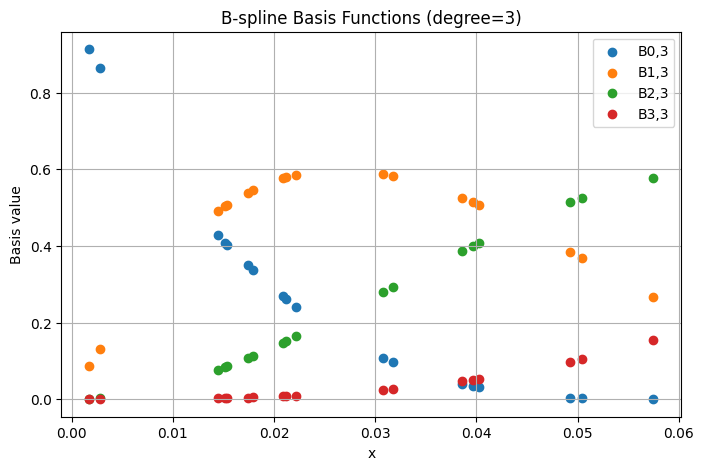

In [6]:
plt.figure(figsize=(8, 5))
for i in range(4):
    plt.scatter(model.X[0,:,0].detach().numpy(), model.B_x[i].detach().numpy(), label=f"B{i},{model.degree}")

# for x in knot_vector[3:20]:
#     plt.axvline(x=x, color='gray', linestyle=':')
plt.title(f"B-spline Basis Functions (degree={model.degree})")
plt.xlabel("x")
plt.ylabel("Basis value")
plt.legend()
plt.grid(True)
plt.show()


In [5]:
torch.manual_seed(42)
colloc_points = 5000
# x = torch.linspace(0,0.99,colloc_points, requires_grad=True).reshape(colloc_points,1)
# y = torch.linspace(0,0.99,colloc_points, requires_grad=True).reshape(colloc_points,1)
###########Changes#########
# X = 0.999*torch.rand(colloc_points,2)+0.001
X = torch.rand(colloc_points,2)
##########Changes###########
X.requires_grad_(True)
# X.to(device)

tensor([[0.8823, 0.9150],
        [0.3829, 0.9593],
        [0.3904, 0.6009],
        ...,
        [0.9278, 0.5794],
        [0.8308, 0.2181],
        [0.9120, 0.4111]], requires_grad=True)

In [10]:
X.shape

torch.Size([5000, 2])

In [6]:
model.X[0]

tensor([[0.0212, 0.0098],
        [0.0493, 0.0102],
        [0.0318, 0.0280],
        [0.0307, 0.0187],
        [0.0222, 0.0074],
        [0.0028, 0.0469],
        [0.0018, 0.0531],
        [0.0154, 0.0342],
        [0.0145, 0.0243],
        [0.0386, 0.0022],
        [0.0208, 0.0187],
        [0.0179, 0.0369],
        [0.0575, 0.0433],
        [0.0397, 0.0257],
        [0.0504, 0.0178],
        [0.0152, 0.0458],
        [0.0174, 0.0060],
        [0.0402, 0.0480]], grad_fn=<SelectBackward0>)

In [5]:
model.coeffs_trainable[1:4,1:4]

tensor([[0.4414, 0.2969, 0.8317],
        [0.3644, 0.7104, 0.9464],
        [0.1587, 0.6542, 0.3278]], grad_fn=<SliceBackward0>)

In [6]:
epochs = 20000

###########Changes#################
learning_rate=1e-3
# learning_rate=1e-4
###########Changes#################

# Right-hand side of Poisson equation
def f(x, y):
    return -2 * (np.pi ** 2) * torch.sin(np.pi * x) * torch.sin(np.pi * y)

loss_vec = []

###########Changes#################
optimizer = torch.optim.Adam([model.coeffs_trainable], lr=learning_rate)
###########Changes#################

for epoch in range(epochs):
    
    ###########Changes#################
    optimizer.zero_grad()
    ###########Changes#################
    u = model.forward(0)
    grads = torch.autograd.grad(u, model.x, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_x = grads[:, 0]
    u_y = grads[:, 1]
    u_xx = torch.autograd.grad(u_x, model.x, torch.ones_like(u_x), create_graph=True)[0][:, 0]
    u_yy = torch.autograd.grad(u_y, model.x, torch.ones_like(u_y), create_graph=True)[0][:, 1]

    source = f(model.X[0,:,0], model.X[0,:,1])
    # Residual loss
    res = u_xx + u_yy - source
    
    loss = torch.mean(res**2)
    
    loss.backward()
    ###########Changes#################
    optimizer.step()
    # # Manually update parameters using the gradients
    # with torch.no_grad():
    #     model.coeffs -= learning_rate * model.coeffs.grad
    # # Zero the gradients after each update
    # model.coeffs.grad.zero_()
    # # x.grad.zero_()
    ###########Changes#################

    loss_vec.append(loss.item())
    # Print loss and parameters every 100 iterations
    if (epoch + 1) % 5 == 0:
        print(f'Epoch [{epoch + 1}/{epochs}], Loss: {loss.item()}')

Epoch [5/20000], Loss: 366590.6875
Epoch [10/20000], Loss: 356400.625
Epoch [15/20000], Loss: 346400.3125
Epoch [20/20000], Loss: 336599.875
Epoch [25/20000], Loss: 327006.65625
Epoch [30/20000], Loss: 317625.65625
Epoch [35/20000], Loss: 308458.5
Epoch [40/20000], Loss: 299505.53125
Epoch [45/20000], Loss: 290765.5
Epoch [50/20000], Loss: 282235.90625
Epoch [55/20000], Loss: 273914.09375
Epoch [60/20000], Loss: 265796.71875
Epoch [65/20000], Loss: 257880.859375
Epoch [70/20000], Loss: 250163.28125
Epoch [75/20000], Loss: 242641.078125
Epoch [80/20000], Loss: 235311.171875
Epoch [85/20000], Loss: 228170.5
Epoch [90/20000], Loss: 221216.046875
Epoch [95/20000], Loss: 214444.578125
Epoch [100/20000], Loss: 207853.046875
Epoch [105/20000], Loss: 201438.390625
Epoch [110/20000], Loss: 195197.4375
Epoch [115/20000], Loss: 189126.9375
Epoch [120/20000], Loss: 183223.859375
Epoch [125/20000], Loss: 177485.15625
Epoch [130/20000], Loss: 171907.546875
Epoch [135/20000], Loss: 166488.0625
Epoch 

KeyboardInterrupt: 

In [8]:
model.coeffs_trainable

tensor([[0.8823, 0.9150, 0.3829, 0.9593],
        [0.3904, 0.0648, 0.1943, 0.3650],
        [0.9408, 0.1943, 0.5828, 1.0958],
        [0.8694, 0.4112, 1.2341, 2.3249]], requires_grad=True)

In [10]:
model.coeffs_trainable

tensor([[0.8823, 0.9150, 0.3829, 0.9593],
        [0.3904, 0.0648, 0.1945, 0.3654],
        [0.9408, 0.1945, 0.5835, 1.0961],
        [0.8694, 0.4118, 1.2354, 2.3293]], requires_grad=True)

In [4]:
knot_vector=model.knot_vector[3:-3]
nel = (knot_vector.shape[0]-1)**2
degree = model.degree
n_basis = model.n_basis

In [5]:
# rows elements, columns coordinates, x1, x2, y1, y2
el_coordinates = []
for i in range(knot_vector.shape[0]-1):
    for j in range(knot_vector.shape[0]-1):
        row = torch.tensor([knot_vector[i], knot_vector[i+1], knot_vector[j], knot_vector[j+1]])
        el_coordinates.append(row)

el_coordinates = torch.stack(el_coordinates, dim=0)

In [7]:
# In every element exactly p+1 basis function have support(non-zero), fro p=3 4 basis functions
connectivity = []
for i in range(model.n_basis-3):
    for j in range(model.n_basis-3):
        row = torch.tensor([i, i+(model.degree), j, j+(model.degree)])
        connectivity.append(row)

# connectivity = torch.stack(connectivity, dim=0)

In [13]:
connectivity = []
for i in range(model.n_basis - 3):
    for j in range(model.n_basis - 3):
        row = [i, i + model.degree, j, j + model.degree]
        connectivity.append(row)


In [11]:
num_points=18
X = torch.zeros(nel,num_points,2)
for i in range(el_coordinates.shape[0]):

    i_range = (el_coordinates[i,0], el_coordinates[i,1])
    j_range = (el_coordinates[i,2], el_coordinates[i,3])

    i_vals = i_range[0] + (i_range[1] - i_range[0]) * torch.rand((num_points, 1))
    j_vals = j_range[0] + (j_range[1] - j_range[0]) * torch.rand((num_points, 1))
    X[i] = torch.cat([i_vals, j_vals], dim=1)
